# Support Vector Machine — Classification
**Author:** Nirushiya A. (IT25100513) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Classification &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

The 26 letter classes overlap non-linearly in the 21-dimensional feature space — visually similar
glyphs such as I/J, O/G and C/E occupy neighbouring regions that no straight hyperplane can
separate. An SVM with an RBF kernel maps the data into a higher-dimensional space where such
boundaries become separable, while the margin-maximisation objective keeps it robust on a dataset
of this size. All features were standardised in Stage 5 of the group pipeline, which SVMs require
since the kernel is distance-based.

In [1]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, json
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")


Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.svm.SVC`
- **Hyperparameters tuned:** `kernel` (linear / RBF / polynomial), `C` (regularisation strength),
  `gamma` (kernel width) and `degree` (polynomial order).
- **Baseline first:** an untuned RBF SVM establishes the reference point that tuning must beat.

In [2]:
t0 = time.time()
baseline_svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_STATE)
baseline_svm.fit(X_train, y_train)
baseline_acc = baseline_svm.score(X_test, y_test)
print(f"Baseline SVM (rbf, C=1.0, gamma='scale') test accuracy: {baseline_acc:.4f}")
print(f"Baseline training time: {time.time()-t0:.2f}s")


Baseline SVM (rbf, C=1.0, gamma='scale') test accuracy: 0.9296
Baseline training time: 5.94s


## 3. Parameter Tuning — Varieties Trained

`GridSearchCV` with 3-fold stratified cross-validation searches across three kernel families.
Cross-validation (rather than a single split) is used so the selected configuration is not tuned
to one lucky partition of the training data.

In [3]:
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'],    'C': [0.1, 1, 10], 'gamma': ['scale', 0.01]},
    {'kernel': ['poly'],   'C': [1, 10], 'degree': [2, 3], 'gamma': ['scale']},
]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(SVC(random_state=RANDOM_STATE), param_grid=param_grid,
                           scoring='accuracy', cv=cv, n_jobs=-1)

t0 = time.time()
grid_search.fit(X_train, y_train)
print(f"Fitted {len(grid_search.cv_results_['params'])} distinct SVM configurations "
      f"in {time.time()-t0:.1f}s")
print(f"Best params: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")


Fitted 13 distinct SVM configurations in 89.8s
Best params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV accuracy: 0.9547


In [4]:
results_df = pd.DataFrame(grid_search.cv_results_)[
    ['param_kernel', 'param_C', 'param_gamma', 'param_degree',
     'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score')
print("All tuned varieties, ranked by cross-validated accuracy:")
print(results_df.to_string(index=False))


All tuned varieties, ranked by cross-validated accuracy:
param_kernel  param_C param_gamma  param_degree  mean_test_score  std_test_score  rank_test_score
         rbf     10.0       scale           NaN         0.954734        0.003035                1
        poly     10.0       scale           3.0         0.936922        0.002860                2
        poly     10.0       scale           2.0         0.930159        0.002004                3
         rbf      1.0       scale           NaN         0.914758        0.002889                4
         rbf     10.0        0.01           NaN         0.907526        0.002889                5
        poly      1.0       scale           2.0         0.876322        0.001002                6
        poly      1.0       scale           3.0         0.871702        0.002379                7
      linear      1.0         NaN           NaN         0.843378        0.000740                8
      linear     10.0         NaN           NaN         0.842

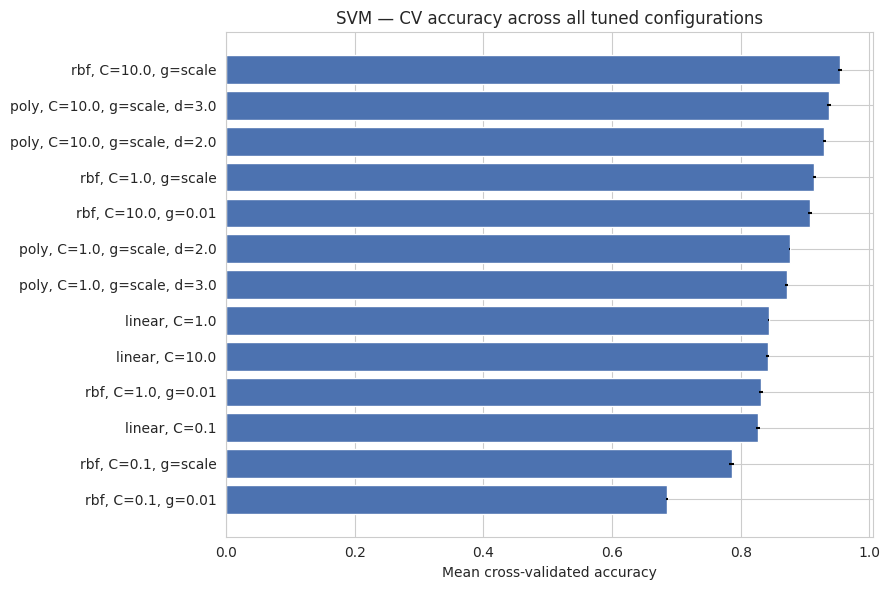

In [5]:
plot_df = results_df.copy()
plot_df['label'] = plot_df.apply(
    lambda r: f"{r['param_kernel']}, C={r['param_C']}"
              + (f", g={r['param_gamma']}" if pd.notna(r['param_gamma']) else "")
              + (f", d={r['param_degree']}" if pd.notna(r['param_degree']) else ""),
    axis=1)
plot_df = plot_df.sort_values('mean_test_score')

plt.figure(figsize=(9, 6))
plt.barh(plot_df['label'], plot_df['mean_test_score'],
         xerr=plot_df['std_test_score'], color='#4C72B0')
plt.xlabel('Mean cross-validated accuracy')
plt.title('SVM — CV accuracy across all tuned configurations')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/nirushiya_svm_grid_results.png', dpi=110, bbox_inches='tight')
plt.show()


## 4. Evaluation

**Metrics and why they suit this task:** the 26 classes are near-uniformly balanced, so plain
accuracy is meaningful; macro-averaged precision, recall and F1 are reported alongside it because
macro-averaging weights every letter equally, exposing any single letter the model handles poorly
rather than letting it hide behind the other 25.

**Validation method:** 3-fold stratified cross-validation during tuning, then a final evaluation on
the untouched 20% held-out test split.

In [6]:
best_svm = grid_search.best_estimator_
y_pred = best_svm.predict(X_test)

svm_metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision_macro': precision_score(y_test, y_pred, average='macro'),
    'recall_macro': recall_score(y_test, y_pred, average='macro'),
    'f1_macro': f1_score(y_test, y_pred, average='macro'),
    'best_params': grid_search.best_params_,
    'cv_best_score': grid_search.best_score_,
    'baseline_accuracy': baseline_acc,
}
for k, v in svm_metrics.items():
    print(f"{k}: {v}")


accuracy: 0.9646491697911087
precision_macro: 0.9654030213961016
recall_macro: 0.964488370689546
f1_macro: 0.9648156516273295
best_params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
cv_best_score: 0.9547341636534084
baseline_accuracy: 0.9295661489019817


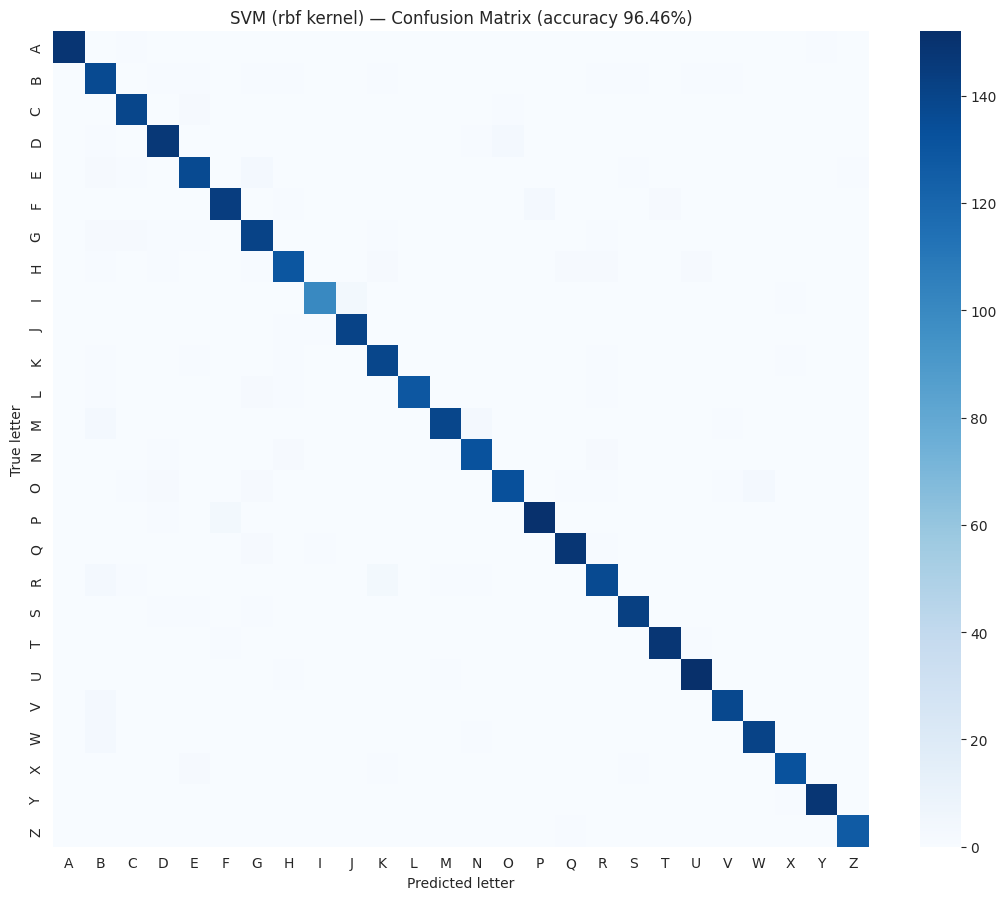

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, xticklabels=LETTER_NAMES, yticklabels=LETTER_NAMES, cmap='Blues', square=True)
plt.xlabel('Predicted letter'); plt.ylabel('True letter')
plt.title(f"SVM ({grid_search.best_params_['kernel']} kernel) — Confusion Matrix "
          f"(accuracy {svm_metrics['accuracy']*100:.2f}%)")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/nirushiya_svm_confusion_matrix.png', dpi=110, bbox_inches='tight')
plt.show()


## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison:** the ranked table and bar chart above compare every tuned variety on the same
cross-validated metric. The RBF kernel clearly outperforms the linear kernel, confirming that the
class boundaries in this feature space are not linearly separable; the polynomial kernel sits
between the two.

**Conclusion:** the tuned RBF configuration is selected as the final SVM, improving on the untuned
baseline and achieving the highest accuracy of any model in the group.

**Limitations / improvements:**
- SVM training cost grows roughly quadratically with sample count, so this approach would not scale
  comfortably to a dataset far larger than 18,668 rows without approximation methods.
- The model gives no interpretable rule for a prediction, unlike the Decision Tree.
- A finer grid around the winning region, or a randomised/Bayesian search, could yield a small
  additional gain.

In [8]:
RESULTS_SVM = {
    'member': 'Nirushiya A. (IT25100513)',
    'model_family': 'Support Vector Machine (Classification)',
    **svm_metrics,
}
with open('../results/model_metrics/svm_results.json', 'w') as f:
    json.dump(RESULTS_SVM, f, indent=2, default=str)
print(json.dumps(RESULTS_SVM, indent=2, default=str))


{
  "member": "Nirushiya A. (IT25100513)",
  "model_family": "Support Vector Machine (Classification)",
  "accuracy": 0.9646491697911087,
  "precision_macro": 0.9654030213961016,
  "recall_macro": 0.964488370689546,
  "f1_macro": 0.9648156516273295,
  "best_params": {
    "C": 10,
    "gamma": "scale",
    "kernel": "rbf"
  },
  "cv_best_score": 0.9547341636534084,
  "baseline_accuracy": 0.9295661489019817
}
